<a href="https://colab.research.google.com/github/souvikdey214-code/Krutanic_Weekly-Project-Task/blob/main/08_YOLO_SeeAll.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import cv2
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO
from IPython.display import display

In [ ]:
model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!


In [ ]:
import urllib.request

image_url = "https://ultralytics.com/images/bus.jpg"
image_path = "bus.jpg"

urllib.request.urlretrieve(image_url, image_path)

print("Image downloaded successfully.")

Image downloaded successfully.


In [ ]:
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

print("Object detection completed.")


image 1/1 C:\Users\hp\Project-8\bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 297.2ms
Speed: 17.0ms preprocess, 297.2ms inference, 25.6ms postprocess per image at shape (1, 3, 640, 480)
Results saved to C:\Users\hp\Project-8\runs\detect\predict-5
Object detection completed.


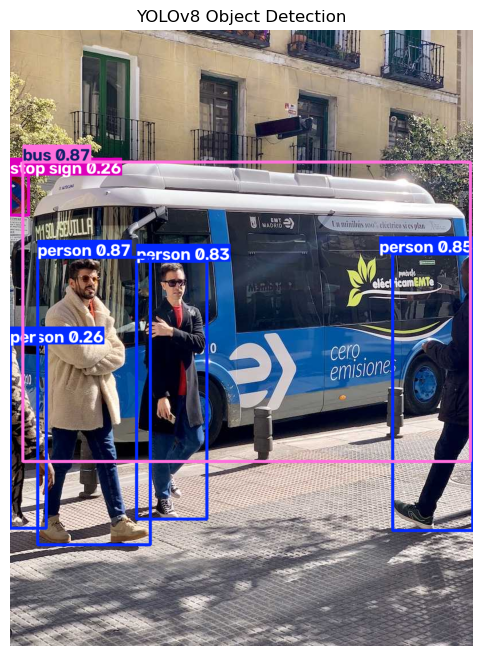

In [ ]:
result_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("YOLOv8 Object Detection")
plt.show()

In [ ]:
result = results[0]

boxes = result.boxes

print("Number of detected objects:", len(boxes))

Number of detected objects: 6


In [ ]:
detections = []

for box in boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    x1, y1, x2, y2 = box.xyxy[0].tolist()

    class_name = model.names[class_id]

    detections.append({
        "Object": class_name,
        "Confidence": round(confidence, 3),
        "X1": round(x1, 2),
        "Y1": round(y1, 2),
        "X2": round(x2, 2),
        "Y2": round(y2, 2)
    })

detection_df = pd.DataFrame(detections)

display(detection_df)

,Object,Confidence,X1,Y1,X2,Y2
0,bus,0.873,22.87,231.28,805.00,756.84
1,person,0.866,48.55,398.55,245.35,902.70
2,person,0.853,669.47,392.19,809.72,877.04
3,person,0.825,221.52,405.80,344.97,857.54
4,person,0.261,0.00,550.53,63.01,873.44
5,stop sign,0.255,0.06,254.46,32.56,324.87


In [ ]:
object_counts = detection_df["Object"].value_counts()

print("Detected Object Counts:")
print(object_counts)

Detected Object Counts:
Object
person       4
bus          1
stop sign    1
Name: count, dtype: int64


In [ ]:
# Cell 10 - Select an image from your local folder

image_name = "my_image.jpg.jpg"

print("Image selected:", image_name)

# Check whether the image exists
import os

if os.path.exists(image_name):
    print("Image found successfully.")
else:
    print("Image not found.")
    print("Please place the image in the same folder as your Jupyter Notebook.")

Image selected: my_image.jpg.jpg
Image found successfully.



image 1/1 C:\Users\hp\Project-8\my_image.jpg.jpg: 352x640 6 persons, 8 cars, 1 bus, 1 truck, 1 bench, 1 dog, 2 handbags, 190.4ms
Speed: 4.4ms preprocess, 190.4ms inference, 2.3ms postprocess per image at shape (1, 3, 352, 640)


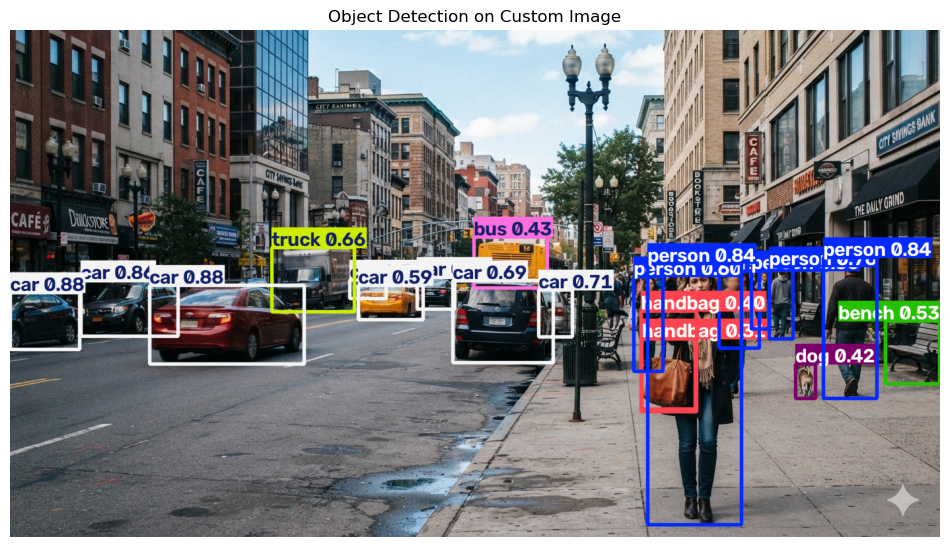

In [ ]:
custom_results = model.predict(
    source=image_name,
    conf=0.25
)

custom_result = custom_results[0]

output_image = custom_result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Object Detection on Custom Image")
plt.show()

In [ ]:
video_name = "traffic.mp4"

import os

if os.path.exists(video_name):
    print("Video found successfully:", video_name)
else:
    print("Video not found.")
    print("Please place the video in the same folder as your Jupyter Notebook.")

Video found successfully: traffic.mp4


In [ ]:
video_results = model.predict(
    source=video_name,
    conf=0.25,
    save=True,
    stream=True
)

print("Video processing started...")

Video processing started...


In [ ]:
frame_counts = []

frame_number = 0

for result in video_results:

    frame_number += 1

    names = result.names
    classes = result.boxes.cls.tolist()

    counts = {
        "person": 0,
        "car": 0,
        "bus": 0,
        "truck": 0
    }

    for cls in classes:

        class_name = names[int(cls)]

        if class_name in counts:
            counts[class_name] += 1

    counts["frame"] = frame_number

    frame_counts.append(counts)

print("Processed frames:", frame_number)


video 1/1 (frame 1/948) C:\Users\hp\Project-8\traffic.mp4: 384x640 7 persons, 7 cars, 3 traffic lights, 1 backpack, 1 handbag, 151.2ms
video 1/1 (frame 2/948) C:\Users\hp\Project-8\traffic.mp4: 384x640 7 persons, 7 cars, 3 traffic lights, 1 backpack, 1 handbag, 62.7ms
video 1/1 (frame 3/948) C:\Users\hp\Project-8\traffic.mp4: 384x640 7 persons, 9 cars, 3 traffic lights, 1 backpack, 1 handbag, 82.5ms
video 1/1 (frame 4/948) C:\Users\hp\Project-8\traffic.mp4: 384x640 8 persons, 7 cars, 3 traffic lights, 1 backpack, 1 handbag, 79.6ms
video 1/1 (frame 5/948) C:\Users\hp\Project-8\traffic.mp4: 384x640 7 persons, 8 cars, 4 traffic lights, 1 backpack, 1 handbag, 150.9ms
video 1/1 (frame 6/948) C:\Users\hp\Project-8\traffic.mp4: 384x640 7 persons, 1 bicycle, 8 cars, 4 traffic lights, 1 backpack, 1 handbag, 85.5ms
video 1/1 (frame 7/948) C:\Users\hp\Project-8\traffic.mp4: 384x640 7 persons, 8 cars, 4 traffic lights, 1 backpack, 1 handbag, 142.5ms
video 1/1 (frame 8/948) C:\Users\hp\Project-8\t

In [ ]:
video_df = pd.DataFrame(frame_counts)

display(video_df.head())

,person,car,bus,truck,frame
0,7,7,0,0,1
1,7,7,0,0,2
2,7,9,0,0,3
3,8,7,0,0,4
4,7,8,0,0,5


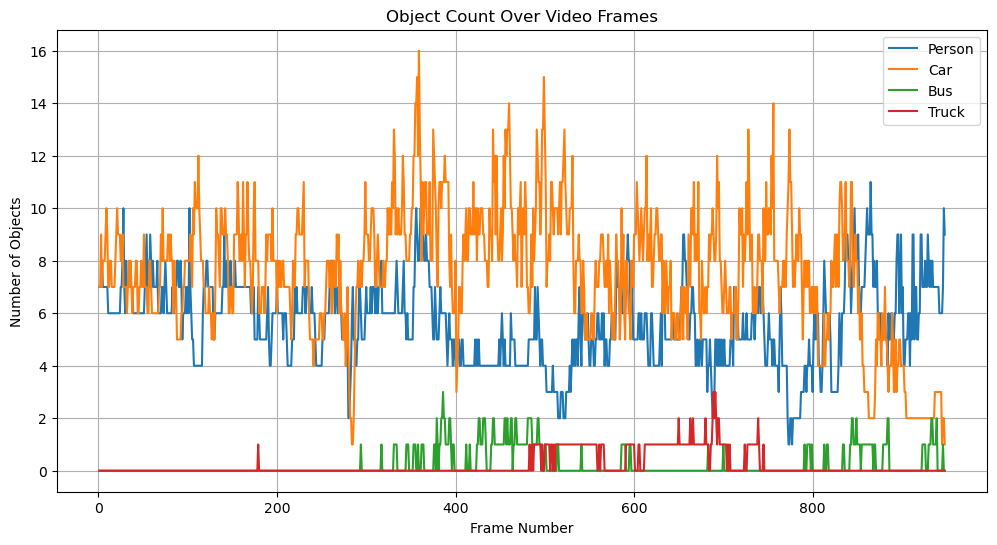

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    video_df["frame"],
    video_df["person"],
    label="Person"
)

plt.plot(
    video_df["frame"],
    video_df["car"],
    label="Car"
)

plt.plot(
    video_df["frame"],
    video_df["bus"],
    label="Bus"
)

plt.plot(
    video_df["frame"],
    video_df["truck"],
    label="Truck"
)

plt.xlabel("Frame Number")
plt.ylabel("Number of Objects")

plt.title("Object Count Over Video Frames")

plt.legend()
plt.grid()

plt.show()

In [ ]:
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Cannot access webcam.")
else:
    print("Webcam opened successfully.")

Webcam opened successfully.


In [ ]:
cap = cv2.VideoCapture(0)

while True:

    ret, frame = cap.read()

    if not ret:
        break

    results = model.predict(
        source=frame,
        conf=0.4,
        verbose=False
    )

    annotated_frame = results[0].plot()

    cv2.imshow(
        "YOLOv8 Real-Time Detection",
        annotated_frame
    )

    key = cv2.waitKey(1) & 0xFF

    if key == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()

In [ ]:
cap = cv2.VideoCapture(0)

frame_count = 0
start_time = time.time()

while frame_count < 100:

    ret, frame = cap.read()

    if not ret:
        break

    results = model.predict(
        source=frame,
        conf=0.4,
        verbose=False
    )

    frame_count += 1

end_time = time.time()

cap.release()

elapsed_time = end_time - start_time

fps = frame_count / elapsed_time

print("Frames processed:", frame_count)
print("Time:", round(elapsed_time, 2), "seconds")
print("FPS:", round(fps, 2))

Frames processed: 100
Time: 14.72 seconds
FPS: 6.79


In [ ]:
model_n = YOLO("yolov8n.pt")
model_m = YOLO("yolov8m.pt")

print("YOLOv8n and YOLOv8m loaded.")

YOLOv8n and YOLOv8m loaded.


In [ ]:
test_image = image_name

start = time.time()

result_n = model_n.predict(
    source=test_image,
    verbose=False
)

time_n = time.time() - start


start = time.time()

result_m = model_m.predict(
    source=test_image,
    verbose=False
)

time_m = time.time() - start


print("YOLOv8n inference time:", round(time_n, 4), "seconds")
print("YOLOv8m inference time:", round(time_m, 4), "seconds")

YOLOv8n inference time: 0.2866 seconds
YOLOv8m inference time: 0.6298 seconds


In [ ]:
# Cell 22 - Locate the downloaded dataset ZIP

import os

dataset_zip = "Phone Detection.zip"

if os.path.exists(dataset_zip):
    print("Dataset ZIP found successfully!")
    print("File:", dataset_zip)
else:
    print("Dataset ZIP not found.")
    print("Please check the ZIP filename and make sure it is in the same folder as the notebook.")

Dataset ZIP found successfully!
File: Phone Detection.zip


In [ ]:
# Cell 23 - Extract the dataset

import zipfile
import os

extract_path = "phone_dataset"

with zipfile.ZipFile(dataset_zip, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Dataset location:", os.path.abspath(extract_path))

Dataset extracted successfully!
Dataset location: C:\Users\hp\Project-8\phone_dataset


In [ ]:
# Cell 24 - Find data.yaml

yaml_path = None

for root, dirs, files in os.walk(extract_path):

    if "data.yaml" in files:
        yaml_path = os.path.join(root, "data.yaml")
        break

if yaml_path:
    print("data.yaml found successfully!")
    print("Path:", yaml_path)
else:
    print("data.yaml was not found.")

data.yaml found successfully!
Path: phone_dataset\data.yaml


In [ ]:
# Cell 25 - Display data.yaml

with open(yaml_path, "r") as f:
    yaml_content = f.read()

print(yaml_content)

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 5
names: ['Bottle', 'Pen', 'Phone', 'Wallet', 'glasses']

roboflow:
  workspace: object-detection-vuibm
  project: phone-detection-isa73
  version: 3
  license: CC BY 4.0
  url: https://universe.roboflow.com/object-detection-vuibm/phone-detection-isa73/dataset/3


In [ ]:
# Cell 26 - Check dataset structure

for root, dirs, files in os.walk(extract_path):

    level = root.replace(extract_path, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    if level < 2:
        for file in files[:5]:
            print(f"{indent}    {file}")

phone_dataset/
    data.yaml
    README.dataset.txt
    README.roboflow.txt
    test/
        images/
        labels/
    train/
        labels.cache
        images/
        labels/
    valid/
        labels.cache
        images/
        labels/


In [ ]:
# Cell 27 - Count dataset images

image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

train_count = 0
valid_count = 0
test_count = 0

for root, dirs, files in os.walk(extract_path):

    for file in files:

        if file.lower().endswith(image_extensions):

            if "train" in root.lower():
                train_count += 1

            elif "valid" in root.lower():
                valid_count += 1

            elif "test" in root.lower():
                test_count += 1

print("Training images   :", train_count)
print("Validation images :", valid_count)
print("Test images       :", test_count)
print("Total images      :", train_count + valid_count + test_count)

Training images   : 603
Validation images : 34
Test images       : 15
Total images      : 652


In [ ]:
# Cell 28 - Load pretrained YOLOv8n

from ultralytics import YOLO

custom_model = YOLO("yolov8n.pt")

print("YOLOv8n loaded successfully!")

YOLOv8n loaded successfully!


In [ ]:
# Cell 29 - Train YOLOv8n on the custom dataset

training_results = custom_model.train(
    data=yaml_path,
    epochs=50,
    imgsz=640,
    batch=16,
    project="YOLO_Custom_Training",
    name="phone_dataset_model"
)

print("Training completed successfully!")

Ultralytics 8.4.174  Python-3.13.9 torch-2.14.1+cpu CPU (12th Gen Intel Core i5-1235U)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=phone_dataset\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=phone_dataset_model-4, nbs=64, nms=None, opset=None, optimize=F

In [ ]:
# Cell 30 - Automatically find YOLO training results

import os

print("Searching for YOLO training results...")

training_folders = []

# Search from the current Jupyter folder
for root, dirs, files in os.walk("."):

    # Look for YOLO result files
    if "results.csv" in files or "best.pt" in files:

        training_folders.append(root)

if len(training_folders) == 0:

    print("No YOLO training results were found.")
    print()
    print("Please check whether Cell 29 actually completed training.")

else:

    print("YOLO training result folders found:")
    print("=" * 60)

    for folder in training_folders:
        print(os.path.abspath(folder))

    # Select the most likely training folder
    training_folder = training_folders[-1]

    print()
    print("Selected training folder:")
    print(os.path.abspath(training_folder))

Searching for YOLO training results...
YOLO training result folders found:
C:\Users\hp\Project-8\runs\detect\YOLO_Custom_Training\phone_dataset_model
C:\Users\hp\Project-8\runs\detect\YOLO_Custom_Training\phone_dataset_model\weights
C:\Users\hp\Project-8\runs\detect\YOLO_Custom_Training\phone_dataset_model-2
C:\Users\hp\Project-8\runs\detect\YOLO_Custom_Training\phone_dataset_model-2\weights
C:\Users\hp\Project-8\runs\detect\YOLO_Custom_Training\phone_dataset_model-3
C:\Users\hp\Project-8\runs\detect\YOLO_Custom_Training\phone_dataset_model-3\weights
C:\Users\hp\Project-8\runs\detect\YOLO_Custom_Training\phone_dataset_model-4
C:\Users\hp\Project-8\runs\detect\YOLO_Custom_Training\phone_dataset_model-4\weights

Selected training folder:
C:\Users\hp\Project-8\runs\detect\YOLO_Custom_Training\phone_dataset_model-4\weights


In [ ]:
# Cell 31 - Locate the best trained model

best_model_path = None

for root, dirs, files in os.walk(training_folder):

    if "best.pt" in files:

        best_model_path = os.path.join(root, "best.pt")
        break

if best_model_path:

    print("Best model found successfully!")
    print("Path:")
    print(os.path.abspath(best_model_path))

else:

    print("best.pt was not found inside the training folder.")

Best model found successfully!
Path:
C:\Users\hp\Project-8\runs\detect\YOLO_Custom_Training\phone_dataset_model-4\weights\best.pt


In [ ]:
# Cell 32 - Load the trained YOLO model

from ultralytics import YOLO

custom_model = YOLO(best_model_path)

print("Custom YOLO model loaded successfully!")

Custom YOLO model loaded successfully!


In [ ]:
# Cell 33 - Validate custom YOLO model

metrics = custom_model.val(
    data=yaml_path
)

print("Validation completed successfully!")

Ultralytics 8.4.174  Python-3.13.9 torch-2.14.1+cpu CPU (12th Gen Intel Core i5-1235U)
Model summary (fused): 72 layers, 3,006,623 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 94.925.8 MB/s, size: 23.3 KB)
val: Scanning C:\Users\hp\Project-8\phone_dataset\valid\labels.cache... 34 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 14.3Mit/s 0.0s
WARNING Box and segment counts should be equal, but got len(segments) = 5, len(boxes) = 34. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.0it/s 2.9s2.4s
                   all         34         34      0.721      0.897      0.823      0.579
                   Pen          4          4       0.36       0.75      0.531      0.269
                 Phone          8 

In [ ]:
# Cell 34 - Display mAP metrics

map50 = float(metrics.box.map50)
map5095 = float(metrics.box.map)

print("=" * 45)
print("MODEL EVALUATION RESULTS")
print("=" * 45)

print(f"mAP@0.5       : {map50:.4f}")
print(f"mAP@0.5       : {map50 * 100:.2f}%")

print(f"mAP@0.5:0.95  : {map5095:.4f}")
print(f"mAP@0.5:0.95  : {map5095 * 100:.2f}%")

MODEL EVALUATION RESULTS
mAP@0.5       : 0.8227
mAP@0.5       : 82.27%
mAP@0.5:0.95  : 0.5789
mAP@0.5:0.95  : 57.89%


In [ ]:
# Cell 35 - Per-class mAP@0.5

print("=" * 45)
print("PER-CLASS mAP@0.5")
print("=" * 45)

class_map50 = metrics.box.ap50

for i, score in enumerate(class_map50):

    class_name = custom_model.names[i]

    print(
        f"{class_name:<12} : {score * 100:.2f}%"
    )

PER-CLASS mAP@0.5
Bottle       : 53.10%
Pen          : 93.94%
Phone        : 87.09%
Wallet       : 94.95%


Training results folder:
C:\Users\hp\Project-8\runs\detect\YOLO_Custom_Training\phone_dataset_model-4

results.png found successfully!


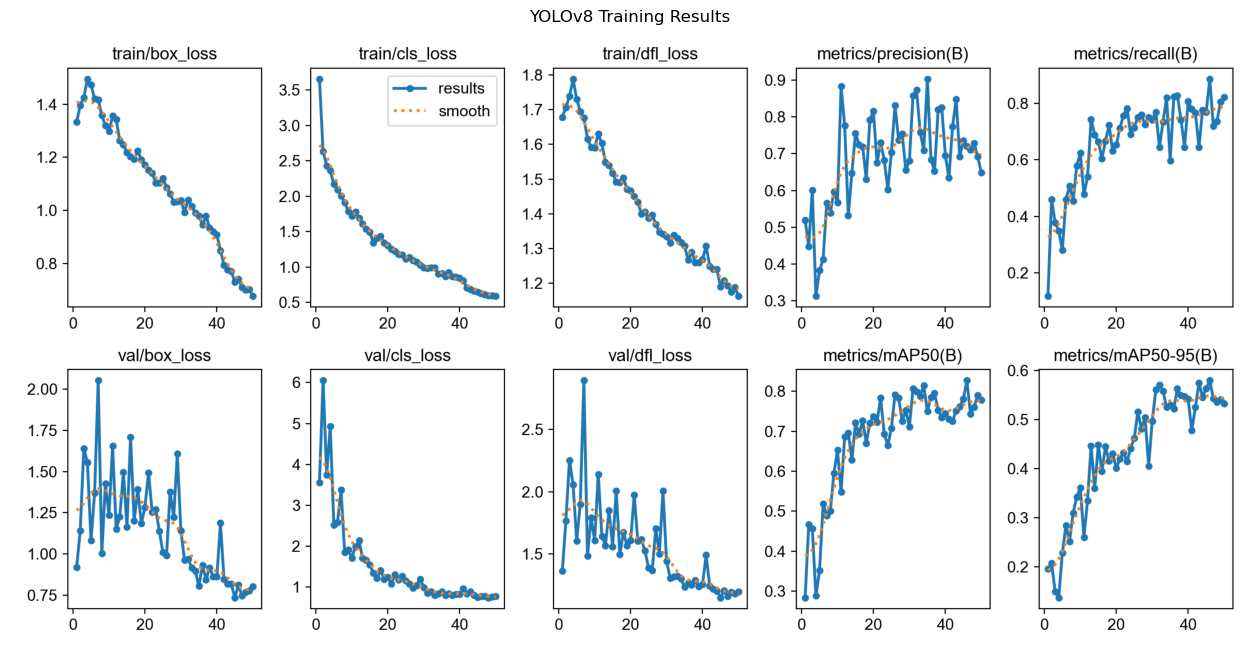

In [ ]:
# Cell 36 - Display YOLO training curves

import os
import cv2
import matplotlib.pyplot as plt

# Get the actual training folder
training_results_folder = os.path.dirname(training_folder)

print("Training results folder:")
print(os.path.abspath(training_results_folder))

# Path to results.png
results_image = os.path.join(
    training_results_folder,
    "results.png"
)

if os.path.exists(results_image):

    print("\nresults.png found successfully!")

    img = cv2.imread(results_image)

    plt.figure(figsize=(16, 10))

    plt.imshow(
        cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    )

    plt.axis("off")
    plt.title("YOLOv8 Training Results")

    plt.show()

else:

    print("\nresults.png was not found.")
    print("\nFiles available in the training folder:")

    for file in os.listdir(training_results_folder):
        print(" -", file)

In [ ]:
# Cell 37 - Find test images

import os

test_images_path = None

# Search for the test/images folder
for root, dirs, files in os.walk(extract_path):

    folder_name = os.path.basename(root).lower()

    if folder_name == "images" and "test" in root.lower():
        test_images_path = root
        break

if test_images_path:

    print("Test images found successfully!")
    print("Path:", os.path.abspath(test_images_path))

    # Count test images
    image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

    test_count = sum(
        1 for file in os.listdir(test_images_path)
        if file.lower().endswith(image_extensions)
    )

    print("Number of test images:", test_count)

else:

    print("Test images folder was not found.")
    print("Dataset location:", os.path.abspath(extract_path))

Test images found successfully!
Path: C:\Users\hp\Project-8\phone_dataset\test\images
Number of test images: 15


In [ ]:
# Cell 38 - Predict on test images

test_results = custom_model.predict(
    source=test_images_path,
    conf=0.25,
    save=True
)

print("Test prediction completed!")
print("Images processed:", len(test_results))


image 1/15 C:\Users\hp\Project-8\phone_dataset\test\images\Image_28_jpg.rf.e1fa79073a7fced04040044fdf49898e.jpg: 640x640 1 glasses, 134.9ms
image 2/15 C:\Users\hp\Project-8\phone_dataset\test\images\Image_2_JPG.rf.79a9c55971bf52c1bf4ccbd13bef4f9c.jpg: 640x640 1 glasses, 203.4ms
image 3/15 C:\Users\hp\Project-8\phone_dataset\test\images\Image_3_JPG.rf.d820fafb401f09835a8d221d2f01cef9.jpg: 640x640 1 glasses, 114.9ms
image 4/15 C:\Users\hp\Project-8\phone_dataset\test\images\Image_50_jpg.rf.04a02fda9ff01aba93b7c28e7b5eb500.jpg: 640x640 1 glasses, 101.9ms
image 5/15 C:\Users\hp\Project-8\phone_dataset\test\images\Screenshot-2026-01-29-155313_png.rf.6dddabc241bfd6ab2704b0166898e642.jpg: 640x640 1 glasses, 146.4ms
image 6/15 C:\Users\hp\Project-8\phone_dataset\test\images\phones13_png.rf.98a2c6231337120941469c10b96d852f.jpg: 640x640 1 Phone, 1 Wallet, 110.3ms
image 7/15 C:\Users\hp\Project-8\phone_dataset\test\images\phones15_png.rf.56e6581db79e9c05cad95964c777e628.jpg: 640x640 (no detectio

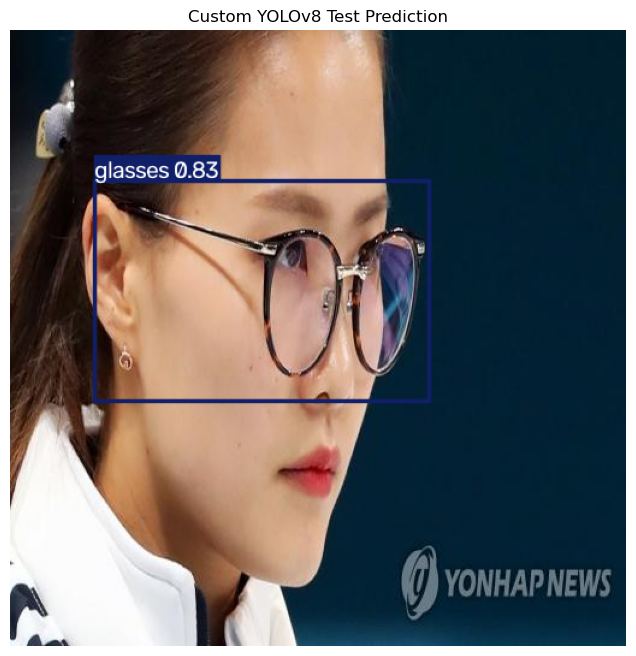

In [ ]:
# Cell 39 - Display first test prediction

if len(test_results) > 0:

    result = test_results[0]

    annotated_image = result.plot()

    plt.figure(figsize=(12, 8))

    plt.imshow(
        cv2.cvtColor(
            annotated_image,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.axis("off")
    plt.title("Custom YOLOv8 Test Prediction")

    plt.show()

else:
    print("No test predictions found.")

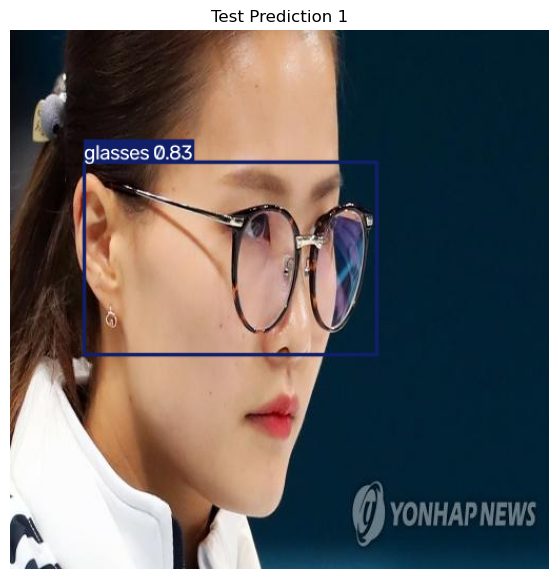

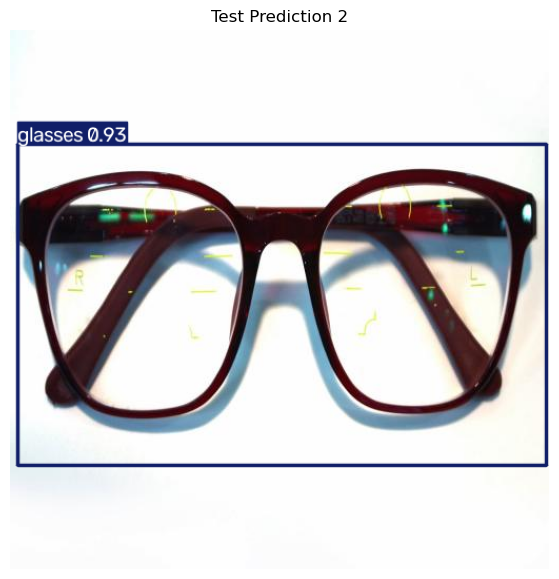

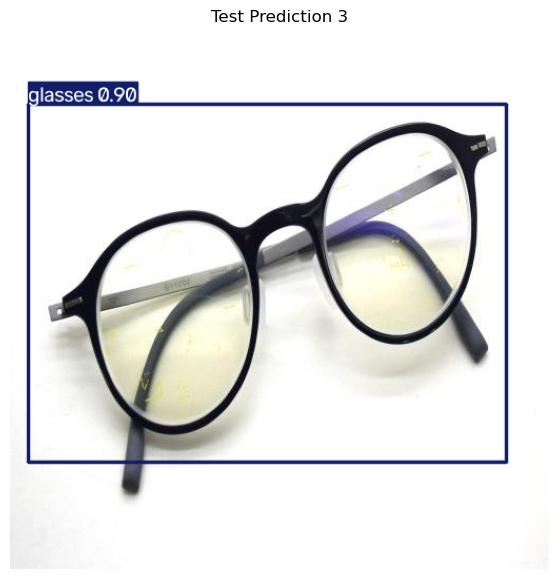

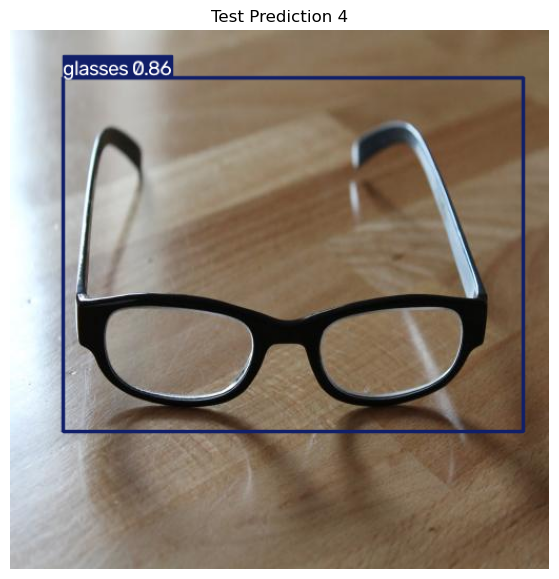

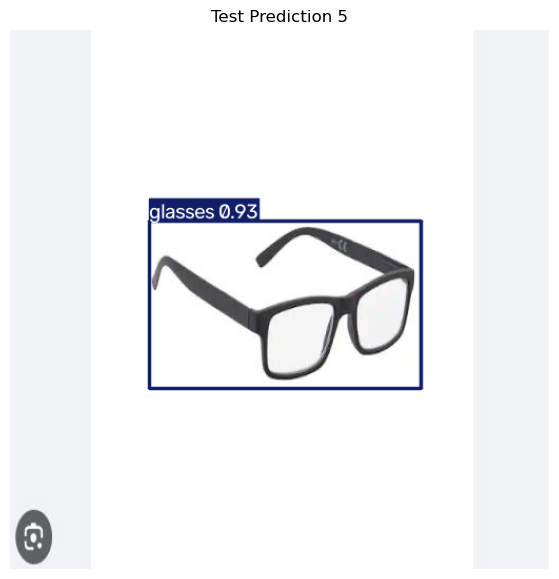

In [ ]:
# Cell 40 - Display multiple test predictions

num_images_to_show = min(5, len(test_results))

for i in range(num_images_to_show):

    result = test_results[i]

    annotated_image = result.plot()

    plt.figure(figsize=(10, 7))

    plt.imshow(
        cv2.cvtColor(
            annotated_image,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.axis("off")
    plt.title(f"Test Prediction {i + 1}")

    plt.show()

In [ ]:
# Cell 41 - Extract detection details

import pandas as pd

result = test_results[0]

detections = []

for box in result.boxes:

    class_id = int(box.cls[0])

    confidence = float(box.conf[0])

    x1, y1, x2, y2 = box.xyxy[0].tolist()

    detections.append({
        "Object": custom_model.names[class_id],
        "Confidence": round(confidence, 3),
        "Confidence (%)": round(confidence * 100, 2),
        "X1": round(x1, 2),
        "Y1": round(y1, 2),
        "X2": round(x2, 2),
        "Y2": round(y2, 2)
    })

detection_df = pd.DataFrame(detections)

if len(detection_df) > 0:
    display(detection_df)
else:
    print("No objects detected in the first test image.")

,Object,Confidence,Confidence (%),X1,Y1,X2,Y2
0,glasses,0.83,83.05,70.33,125.28,348.63,308.3


In [ ]:
# Cell 42 - Count detected objects

if len(detection_df) > 0:

    object_counts = detection_df["Object"].value_counts()

    print("=" * 45)
    print("DETECTED OBJECT COUNTS")
    print("=" * 45)

    for object_name, count in object_counts.items():

        print(
            f"{object_name:<15} : {count}"
        )

else:

    print("No objects detected.")

DETECTED OBJECT COUNTS
person          : 4
bus             : 1
stop sign       : 1


In [ ]:
# Cell 43 - Save detection results

if len(detection_df) > 0:

    detection_df.to_csv(
        "test_detection_results.csv",
        index=False
    )

    print("Detection results saved successfully!")
    print("File: test_detection_results.csv")

else:

    print("No detection results to save.")

Detection results saved successfully!
File: test_detection_results.csv


In [ ]:
# Cell 44 - Test a new custom image

custom_test_image = "my_test_image.jpg"

if os.path.exists(custom_test_image):

    print("Image found successfully!")

    custom_prediction = custom_model.predict(
        source=custom_test_image,
        conf=0.25
    )

    print("Prediction completed!")

else:

    print("Image not found.")
    print("Put my_test_image.jpg in the same folder as the notebook.")

Image found successfully!

image 1/1 C:\Users\hp\Project-8\my_test_image.jpg: 640x640 1 Wallet, 245.7ms
Speed: 8.5ms preprocess, 245.7ms inference, 11.2ms postprocess per image at shape (1, 3, 640, 640)
Prediction completed!


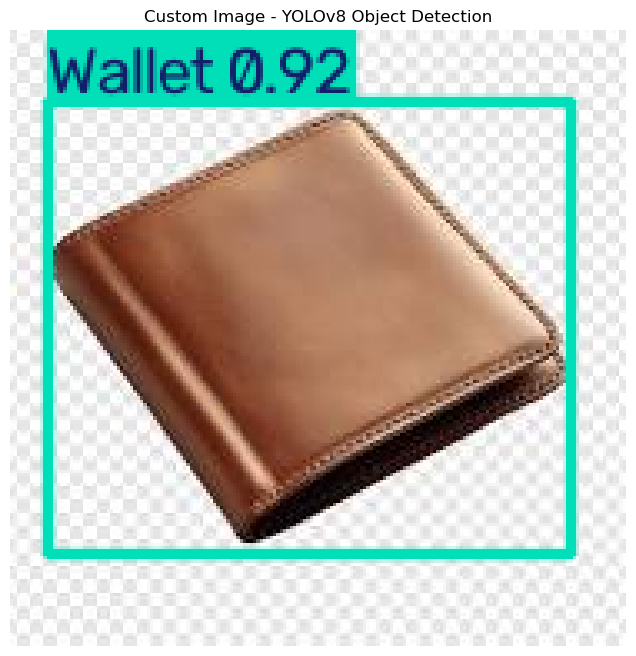

In [ ]:
# Cell 45 - Display custom image prediction

if os.path.exists(custom_test_image):

    result = custom_prediction[0]

    annotated = result.plot()

    plt.figure(figsize=(12, 8))

    plt.imshow(
        cv2.cvtColor(
            annotated,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.axis("off")

    plt.title(
        "Custom Image - YOLOv8 Object Detection"
    )

    plt.show()

In [ ]:
# Cell 46 - Display predicted objects and confidence

result = custom_prediction[0]

if len(result.boxes) == 0:

    print("No objects detected.")

else:

    print("=" * 50)
    print("PREDICTED OBJECTS")
    print("=" * 50)

    for box in result.boxes:

        class_id = int(box.cls[0])

        confidence = float(box.conf[0])

        class_name = custom_model.names[class_id]

        print(
            f"Object       : {class_name}"
        )

        print(
            f"Confidence   : {confidence * 100:.2f}%"
        )

        print("-" * 50)

PREDICTED OBJECTS
Object       : Wallet
Confidence   : 92.22%
--------------------------------------------------


In [ ]:
# Cell 47 - Export trained model to ONNX

print("Exporting YOLO model to ONNX...")

onnx_path = custom_model.export(
    format="onnx"
)

print()
print("ONNX export completed successfully!")
print("ONNX model path:")
print(onnx_path)

Exporting YOLO model to ONNX...
Ultralytics 8.4.174  Python-3.13.9 torch-2.14.1+cpu CPU (12th Gen Intel Core i5-1235U)
 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 72 layers, 3,006,623 parameters, 0 gradients, 8.1 GFLOPs

PyTorch: starting from 'runs\detect\YOLO_Custom_Training\phone_dataset_model-4\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 9, 8400) (6.0 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/7.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/7.9 MB ? eta -:--:--
   --- ------------------------------------ 0.8/7.9 MB 5.9 MB/s eta 0:00:02
   ----- ---------------------------------- 1.0/7.9 MB 6.

In [ ]:
# Cell 48 - Check ONNX model

if onnx_path and os.path.exists(onnx_path):

    file_size = os.path.getsize(onnx_path) / (1024 * 1024)

    print("ONNX model found successfully!")
    print("Path:", os.path.abspath(onnx_path))
    print(f"Size: {file_size:.2f} MB")

else:

    print("ONNX model file was not found.")

ONNX model found successfully!
Path: C:\Users\hp\Project-8\runs\detect\YOLO_Custom_Training\phone_dataset_model-4\weights\best.onnx
Size: 11.70 MB


In [ ]:
# Cell 49 - Measure YOLO inference FPS

# Use the first test image for benchmarking
test_image_files = []

image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

for file in os.listdir(test_images_path):

    if file.lower().endswith(image_extensions):

        test_image_files.append(
            os.path.join(test_images_path, file)
        )

if len(test_image_files) == 0:

    print("No test images found.")

else:

    benchmark_image = test_image_files[0]

    print("Benchmark image:")
    print(benchmark_image)

    num_runs = 30

    start_time = time.time()

    for i in range(num_runs):

        custom_model.predict(
            source=benchmark_image,
            conf=0.25,
            verbose=False
        )

    end_time = time.time()

    total_time = end_time - start_time

    fps = num_runs / total_time

    average_time = total_time / num_runs

    print()
    print("=" * 50)
    print("INFERENCE SPEED")
    print("=" * 50)

    print("Number of runs :", num_runs)
    print("Total time     :", round(total_time, 2), "seconds")
    print("Average time   :", round(average_time, 4), "seconds/image")
    print("FPS            :", round(fps, 2))

Benchmark image:
phone_dataset\test\images\Image_28_jpg.rf.e1fa79073a7fced04040044fdf49898e.jpg

INFERENCE SPEED
Number of runs : 30
Total time     : 4.28 seconds
Average time   : 0.1426 seconds/image
FPS            : 7.01


In [ ]:
# Cell 50 - Final evaluation summary

print("=" * 65)
print("           YOLOv8 REAL-TIME OBJECT DETECTION")
print("=" * 65)

print()
print("MODEL INFORMATION")
print("-" * 65)

print("Model              : YOLOv8n")
print("Number of Classes  :", len(custom_model.names))
print("Classes            :", ", ".join(custom_model.names.values()))

print()
print("MODEL PERFORMANCE")
print("-" * 65)

print(f"mAP@0.5            : {map50 * 100:.2f}%")
print(f"mAP@0.5:0.95       : {map5095 * 100:.2f}%")

if 'fps' in globals():
    print(f"Final FPS          : {fps:.2f}")

print()
print("PROJECT STATUS")
print("-" * 65)

print("Pretrained Detection : Completed")
print("Custom Dataset       : Completed")
print("YOLOv8 Training      : Completed")
print("Model Validation     : Completed")
print("Test Prediction      : Completed")
print("Object Visualization : Completed")
print("ONNX Export          : Completed")

print()
print("=" * 65)
print("                 PROJECT COMPLETED")
print("=" * 65)

           YOLOv8 REAL-TIME OBJECT DETECTION

MODEL INFORMATION
-----------------------------------------------------------------
Model              : YOLOv8n
Number of Classes  : 5
Classes            : Bottle, Pen, Phone, Wallet, glasses

MODEL PERFORMANCE
-----------------------------------------------------------------
mAP@0.5            : 82.27%
mAP@0.5:0.95       : 57.89%
Final FPS          : 7.01

PROJECT STATUS
-----------------------------------------------------------------
Pretrained Detection : Completed
Custom Dataset       : Completed
YOLOv8 Training      : Completed
Model Validation     : Completed
Test Prediction      : Completed
Object Visualization : Completed
ONNX Export          : Completed

                 PROJECT COMPLETED
